# 03 · Patient networks for: new high blood pressure

Question: **will this patient get their first high-blood-pressure diagnosis within a year of leaving hospital?**

We build three networks out of the same hospital stays:

| network | each stay is described by | why |
|---|---|---|
| **honest** | diagnoses from *before* the prediction time | the one you could really use |
| **cheating** | the patient's *whole* record, future included | shows what peeking does |
| **random** | the honest network with its links shuffled (10 times) | what "no real pattern" looks like |

Two stays get a link if each is in the other's top-10 most similar stays (similarity = which diagnoses they share, with rare diagnoses counting more).

In [1]:
import matplotlib.pyplot as plt

from ehrgraph.eval.aggregate import write_aggregate
from ehrgraph.netstats.task_analysis import analyze_task, friendly_table, task_graphs_from_labels
from ehrgraph.project import setup
from ehrgraph.viz import network_figures as nf

p = setup()  # finds the data in data/omop/


nf.apply_style()
TASK = "new_hypertension"

data folder: ~/repos/ehrshot-patient-graphs/data/omop
results go to: ~/repos/ehrshot-patient-graphs/results/aggregate


## Build the networks and measure everything

This takes a couple of minutes. It saves one small summary file (no patient data) for the report.

In [2]:
labels = p.labels(TASK)
nets = task_graphs_from_labels(p.diagnoses, labels, TASK)
results = analyze_task(nets)
write_aggregate(results.rows, p.results / "network_stats_task_b.csv")
print(f"{len(nets.nodes):,} stays, {nets.prevalence:.1%} with the outcome")

3,511 stays, 12.8% with the outcome


## What the networks look like

Each dot is one stay: **purple = new high blood pressure**, grey = no new high blood pressure. Only the biggest connected piece of each network is drawn. If similar patients share outcomes, purple dots should bunch together in the honest and cheating pictures, but not in the random one.

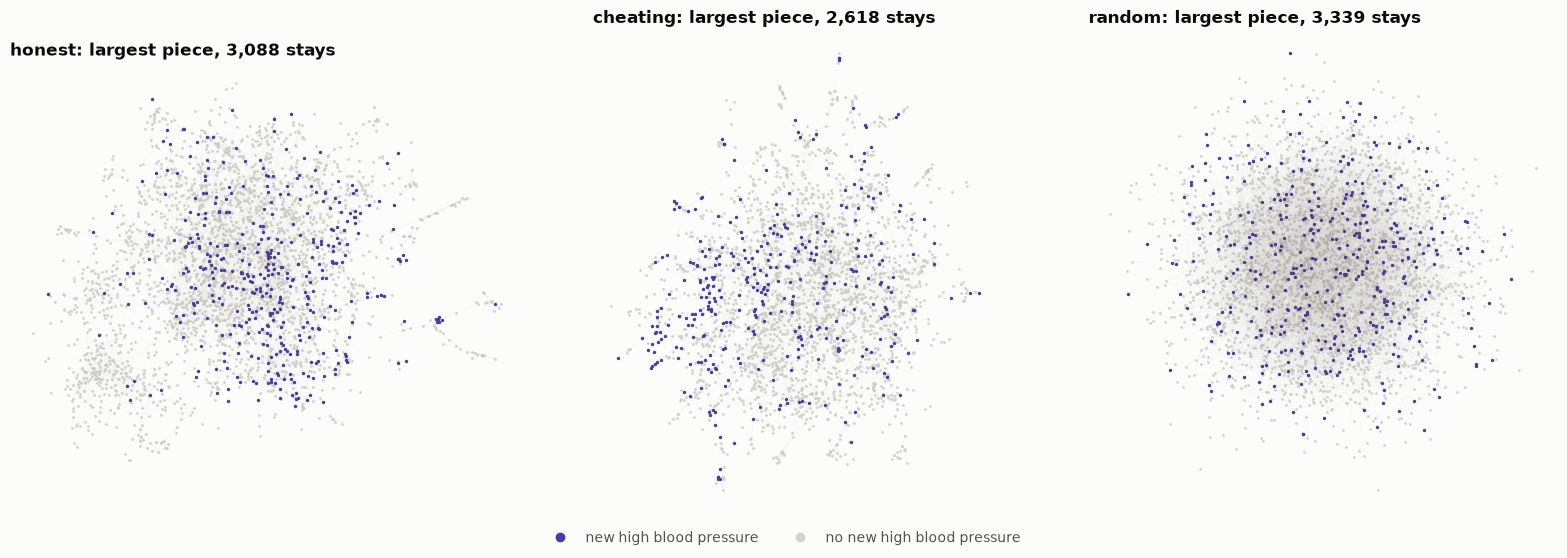

In [3]:
fig = nf.layout_figure(nets, "new high blood pressure", "no new high blood pressure")
nf.save(fig, p.figures / "03_network_pictures.png", dpi=80)
plt.show()

## Basic shape

How the real networks differ from random wiring. Every stay has the same number of links in "honest" and "random", so any difference comes from *who* is linked to whom.

In [4]:
friendly_table(
    results.rows,
    {
        "n_edges": "links",
        "largest_cc_fraction": "share of stays in the biggest piece",
        "transitivity": "closed triangles (friends of friends are linked)",
        "lcc_avg_shortest_path_hops": "average hops between two stays",
        "leiden_modularity": "how cleanly it splits into groups (modularity)",
    },
)

condition,honest,cheating,random (avg of 10),random range
metric,,,,
links,9787.000,8883.000,9787.000,9787 – 9787
share of stays in the biggest piece,0.880,0.746,0.951,0.9496 – 0.951
closed triangles (friends of friends are linked),0.479,0.589,0.002,0.001643 – 0.002457
average hops between two stays,8.076,9.396,4.781,4.771 – 4.795
how cleanly it splits into groups (modularity),0.922,0.958,0.540,0.5391 – 0.542


## Do linked patients share outcomes?

This is the main question. **Homophily** measures how much more often linked stays share the outcome than chance would give (0 = no more than chance). One thing to watch: many links join two stays of the *same patient*, so we also check homophily without those.

In [5]:
friendly_table(
    results.rows,
    {
        "class_insensitive_homophily": "homophily",
        "class_insensitive_homophily_excl_same_patient": "homophily, ignoring same-patient links",
        "same_patient_edge_fraction": "share of links between two stays of the same patient",
        "leiden_outcome_eta_squared": "how much of the outcome the groups explain",
    },
)

condition,honest,cheating,random (avg of 10),random range
metric,,,,
homophily,0.226,0.263,0.002,0.0001153 – 0.009189
"homophily, ignoring same-patient links",0.115,0.154,0.002,5.113e-05 – 0.008775
share of links between two stays of the same patient,0.294,0.295,0.002,0.001272 – 0.002554
how much of the outcome the groups explain,0.074,0.136,0.010,0.005169 – 0.01531


Group the stays into communities (Leiden), then look at how often each group has the outcome. Flat line = groups don't care about the outcome. Spread out = they do.

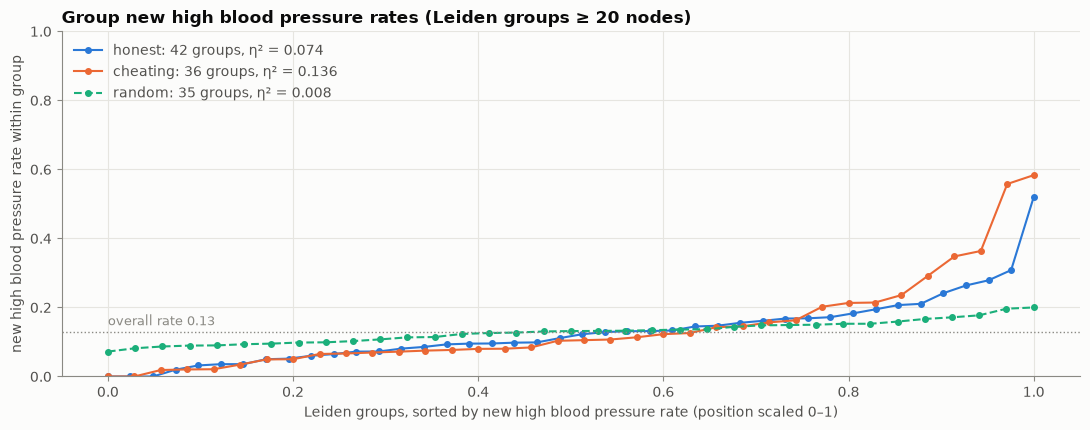

In [6]:
fig = nf.community_outcome_figure(nets, results, "new high blood pressure")
nf.save(fig, p.figures / "03_group_outcome_rates.png")
plt.show()

## What does cheating actually change?

Left: links that only the honest network has, only the cheating one has, or both. How often does each kind join two stays with the same outcome? Right: homophily with and without same-patient links.

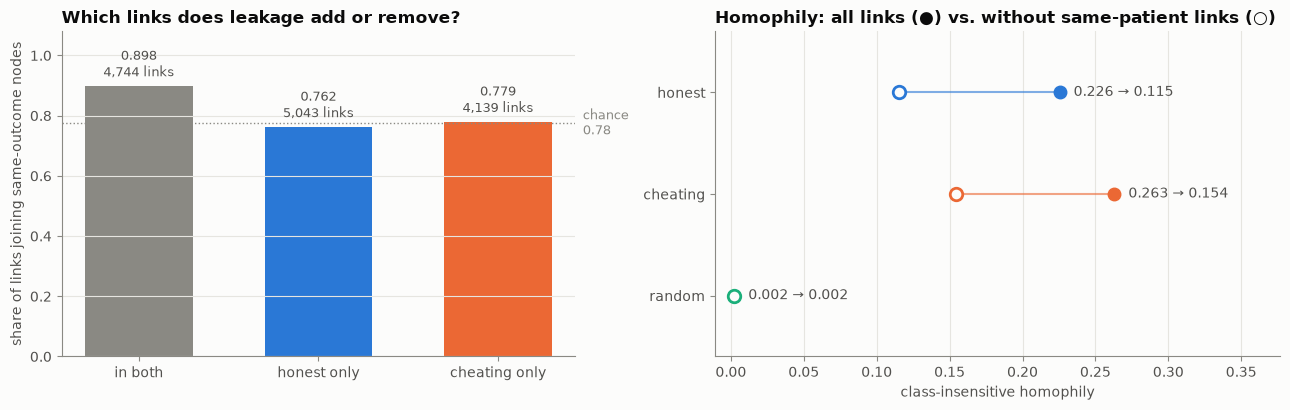

In [7]:
fig = nf.leakage_edges_figure(nets, results)
nf.save(fig, p.figures / "03_what_cheating_changes.png")
plt.show()

And the single diagnosis that best separates the outcome *in the cheating version*. If one stands out a lot, the future record is basically giving the answer away.

In [8]:
top = results.top_leaky_codes.head(5)
top.assign(diagnosis=top.code.map(p.names(top.code)))[
    ["diagnosis", "positive_rate", "negative_rate", "gap"]
].round(2)

,diagnosis,positive_rate,negative_rate,gap
0,Essential hypertension,1.00,0.13,0.87
1,Hyperlipidemia,0.64,0.27,0.37
2,Pleural effusion,0.58,0.29,0.29
3,Acute renal failure syndrome,0.48,0.20,0.28
4,Cardiomegaly,0.42,0.15,0.27


## Being "central" vs the outcome

Quick check whether the most connected or most "in the middle" stays are more likely to have the outcome. 0.5 = no link at all.

In [9]:
friendly_table(
    results.rows,
    {
        "degree_centrality_auroc_vs_label": "most links",
        "betweenness_centrality_auroc_vs_label": "most bridge-like",
        "closeness_centrality_auroc_vs_label": "closest to everyone",
    },
    conditions=("safe", "leaky"),
)

condition,honest,cheating
metric,,
most links,0.494,0.471
most bridge-like,0.534,0.524
closest to everyone,0.581,0.506


## What we learned

- **Same shape as long stay:** clumpy (triangles 0.48 vs 0.002 random), long paths, strong groups (modularity 0.92 vs 0.54).
- **Linked patients share outcomes:** homophily **0.23** vs **0.002** random.
- **Here cheating DOES help:** homophily goes 0.23 → **0.26**, and ignoring same-patient links 0.12 → 0.15 (+34%). The groups also explain almost twice as much of the outcome (0.074 → 0.136).
- **Why:** in the cheating version, "essential hypertension" is in basically **100% of positives vs 13% of negatives**. The future record literally contains the answer. This is exactly the trap we're studying.
- **But the network waters it down a lot.** Even with the answer sitting right there, homophily only goes up by about 0.04. That one diagnosis is very common, and our similarity score down-weights common diagnoses. So how much leakage gets through depends on how you build the network.
- **Same-patient links matter a lot here:** 29% of links, and they agree on the outcome 95% of the time (blood pressure doesn't come and go). They carry about half of the homophily (0.23 → 0.12 without them).
- **Centrality: no signal** (around 0.5).